### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** predict VOC one minute ahead with a Random Forest, using the previous 60 VOC values plus humidity and temperature; then roll the model forward 60 minutes ("next hour").

**Data:** now reads `../data/sensors_1min.csv`. **The saved outputs come from the original run on the old `processed_data.csv`** (3–7 June), whose humidity column was misaligned in time. Re-running will give different numbers.

**Split:** chronological, first 80 % train, last 20 % test (1,389 minutes). **Horizon:** 1 minute (scored); 60 minutes (plotted only, not scored).

**Key result (saved output) vs baselines:**

| Model | R² on the test set |
|---|---|
| Random Forest (100 trees, 60 VOC lags + humidity + temperature) | **0.8540** |
| Baseline: repeat the last value | 0.8244 |
| Baseline: mean of the last 5 minutes | 0.8346 |

The baselines were computed later, during a review of the project. The Random Forest beats them, but only by about 0.02 R².

**Caveats**
- The MinMax scaler is fit on the whole dataset before the split (minor leakage).
- In the saved run the humidity input is misaligned in time (old `processed_data.csv` bug).
- Humidity and temperature at the same minute are used as inputs; in a real forecast they would not be known yet.
- **The 60-minute loop has a bug:** the lag buffer is in the wrong order (oldest first, but the model expects the newest first) and it leaves out the most recent value. Humidity and temperature are frozen. So the "next hour" chart is not a valid forecast, and it was never scored.
- Only R² is printed; the MSE and MAE in our course report were not printed here.


##### CONTENTS: voc Predictions via RandomForestRegressor

In [1]:
# Importing pandas for data manipulation and analysis
import pandas as pd

# Importing numpy for numerical operations
import numpy as np

# Importing RandomForestRegressor for regression modeling
from sklearn.ensemble import RandomForestRegressor

# Importing MinMaxScaler to normalize data to a 0–1 range
from sklearn.preprocessing import MinMaxScaler

# Importing matplotlib for plotting visualizations
import matplotlib.pyplot as plt

# Importing R² score metric to evaluate regression model performance
from sklearn.metrics import r2_score


In [2]:
# Load the dataset from a CSV file into a pandas DataFrame
df = pd.read_csv("../data/sensors_1min.csv")

# Convert the 'time' column to datetime format for proper time series indexing
df['time'] = pd.to_datetime(df['time'])

# Set the 'time' column as the index of the DataFrame (to treat it as a time series)
df.set_index('time', inplace=True)

# Initialize a Min-Max scaler to normalize the data between 0 and 1
scaler = MinMaxScaler()

# Fit the scaler to the data and transform it (scale each feature to [0, 1] range)
scaled = scaler.fit_transform(df)

# Convert the scaled numpy array back to a pandas DataFrame, retaining original column names and time index
df_scaled = pd.DataFrame(scaled, columns=df.columns, index=df.index)


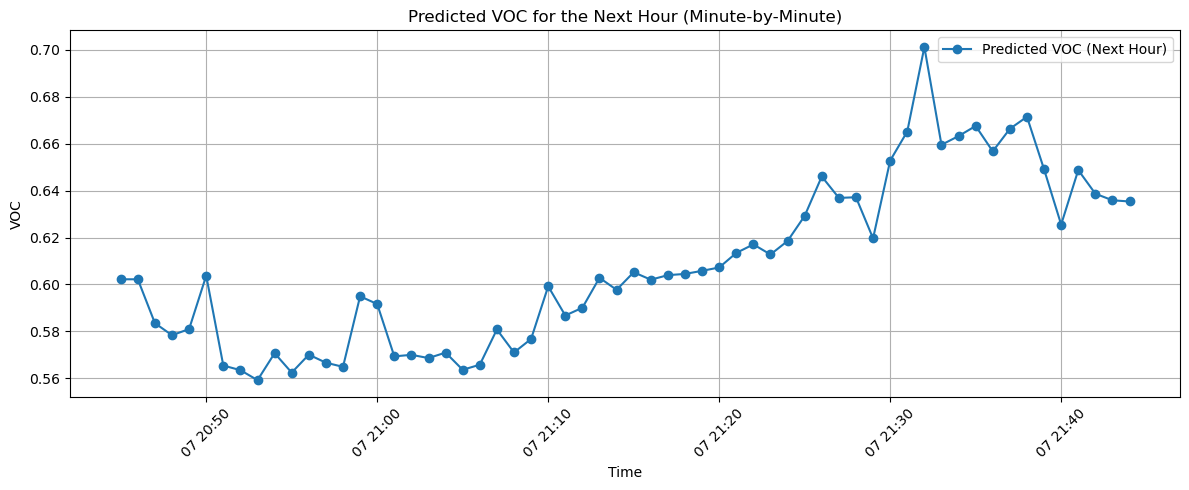

In [3]:
# VOC

# Add lag features for VOC
SEQ_LEN = 60
for i in range(1, SEQ_LEN + 1):
    df_scaled[f'VOC_t-{i}'] = df_scaled['VOC'].shift(i)

df_scaled.dropna(inplace=True)

# Prepare data
X = df_scaled.drop(columns=['VOC'])
y = df_scaled['VOC']
X_train, y_train = X.iloc[:int(0.8 * len(X))], y.iloc[:int(0.8 * len(y))]

# Train model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# --- Forecast Next Hour ---
last_data = df_scaled.iloc[-1].copy()
future_preds = []
future_times = []

# Build a rolling VOC buffer
voc_buffer = [df_scaled.iloc[-1 - i]['VOC'] for i in reversed(range(1, SEQ_LEN + 1))]

# We'll assume humidity and temperature stay the same (last known values)
last_humidity = df.iloc[-1]['humidity']
last_temp = df.iloc[-1]['temperature']
current_time = df.index[-1]

for i in range(60):  # 60 minutes
    input_data = [last_humidity, last_temp] + voc_buffer[-SEQ_LEN:]
    input_scaled = scaler.transform([[last_humidity, last_temp, 0]])[0]
    voc_scaled = input_scaled[2]
    features = np.array(input_data[2:])  # Only lagged VOCs
    full_features = np.concatenate([input_scaled[:2], features])
    pred_norm = model.predict([full_features])[0]

    # Inverse scale the predicted VOC
    dummy_input = np.array([[last_humidity, last_temp, pred_norm]])
    pred_actual = scaler.inverse_transform(dummy_input)[0][2]

    future_preds.append(pred_actual)
    current_time += pd.Timedelta(minutes=1)
    future_times.append(current_time)

    voc_buffer.append(pred_norm)  # Keep normalized VOC values
    voc_buffer = voc_buffer[-SEQ_LEN:]  # Keep size constant

# --- Plot ---
plt.figure(figsize=(12, 5))
plt.plot(future_times, future_preds, label="Predicted VOC (Next Hour)", marker='o')
plt.title("Predicted VOC for the Next Hour (Minute-by-Minute)")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [4]:
# Evaluate model on test set
X_test, y_test = X.iloc[int(0.8 * len(X)):], y.iloc[int(0.8 * len(y)):]
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)

print(f"R² Score on Test Data: {r2:.4f}")

R² Score on Test Data: 0.8540
